In [40]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import seaborn as sns

In [2]:
df = pd.read_csv('smartcart_customers.csv')
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0


In [6]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

# Data-Preproessing

In [8]:
df['Income'] = df['Income'].fillna(df['Income'].median())

# Feature Engineering

In [10]:
df['Age'] = 2026-df['Year_Birth']

In [14]:
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'],dayfirst=True)

reference_date = df['Dt_Customer'].max()
df['Customre_Tenure_Days'] = (reference_date - df['Dt_Customer']).dt.days

In [15]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customre_Tenure_Days
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,88,546,172,88,88,3,8,10,4,7,0,1,69,663
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,1,6,2,1,6,2,1,1,2,5,0,0,72,113
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,49,127,111,21,42,1,8,2,10,4,0,0,61,312
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,4,20,10,3,5,2,2,0,4,6,0,0,42,139
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,43,118,46,27,15,5,5,3,6,5,0,0,45,161


In [16]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Age', 'Customre_Tenure_Days'],
      dtype='object')

In [18]:
# spending
df['Total_Spending'] = df['MntWines']+df['MntFruits']+df['MntMeatProducts']+df['MntFishProducts']+df['MntSweetProducts']+df['MntGoldProds']
df['Total_Children'] = df['Kidhome']+df['Teenhome']

In [19]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customre_Tenure_Days,Total_Spending,Total_Children
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,88,546,172,88,88,3,8,10,4,7,0,1,69,663,1617,0
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,1,6,2,1,6,2,1,1,2,5,0,0,72,113,27,2
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,49,127,111,21,42,1,8,2,10,4,0,0,61,312,776,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,4,20,10,3,5,2,2,0,4,6,0,0,42,139,53,1
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,43,118,46,27,15,5,5,3,6,5,0,0,45,161,422,1


In [23]:
df['Education']=df['Education'].replace({
    "Basic":'Undergraduate',"2n Cycle":'Undergraduate',
    "Graduation":'Graduate',
    "Master":'Postgraduate',"PhD":'Postgraduate'
})

In [24]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customre_Tenure_Days,Total_Spending,Total_Children
0,5524,1957,Graduate,Single,58138.0,0,0,2012-09-04,58,635,88,546,172,88,88,3,8,10,4,7,0,1,69,663,1617,0
1,2174,1954,Graduate,Single,46344.0,1,1,2014-03-08,38,11,1,6,2,1,6,2,1,1,2,5,0,0,72,113,27,2
2,4141,1965,Graduate,Together,71613.0,0,0,2013-08-21,26,426,49,127,111,21,42,1,8,2,10,4,0,0,61,312,776,0
3,6182,1984,Graduate,Together,26646.0,1,0,2014-02-10,26,11,4,20,10,3,5,2,2,0,4,6,0,0,42,139,53,1
4,5324,1981,Postgraduate,Married,58293.0,1,0,2014-01-19,94,173,43,118,46,27,15,5,5,3,6,5,0,0,45,161,422,1


In [25]:
df['Marital_Status'].value_counts()

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

In [26]:
df['Living_with']=df['Marital_Status'].replace({
    "Married":'Partner',"Together":'Partner',
    "Single":'Alone',"Divorced":'Alone',"Widow":'Alone',
    "Alone":'Alone',"Absurd":'Alone',"YOLO":'Alone'
})

In [28]:
df.shape

(2240, 27)

# Drop Columns

In [32]:
cols = ["ID",'Year_Birth','Marital_Status','Kidhome','Teenhome',"Dt_Customer"]
spending_cols = ["MntWines","MntFruits","MntMeatProducts","MntFishProducts","MntSweetProducts","MntGoldProds"]

In [33]:
col_to_drop = cols + spending_cols
df_cleaned = df.drop(columns=col_to_drop)

In [35]:
df_cleaned.shape

(2240, 15)

In [36]:
df_cleaned.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customre_Tenure_Days,Total_Spending,Total_Children,Living_with
0,Graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone
1,Graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone
2,Graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,Partner
3,Graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,Partner
4,Postgraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,Partner


# Outliers

In [38]:
df_cleaned.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customre_Tenure_Days,Total_Spending,Total_Children,Living_with
0,Graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone
1,Graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone
2,Graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,Partner
3,Graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,Partner
4,Postgraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,Partner


In [39]:
cols = ['Income','Recency','Response','Age','Total_Spending','Total_Children']

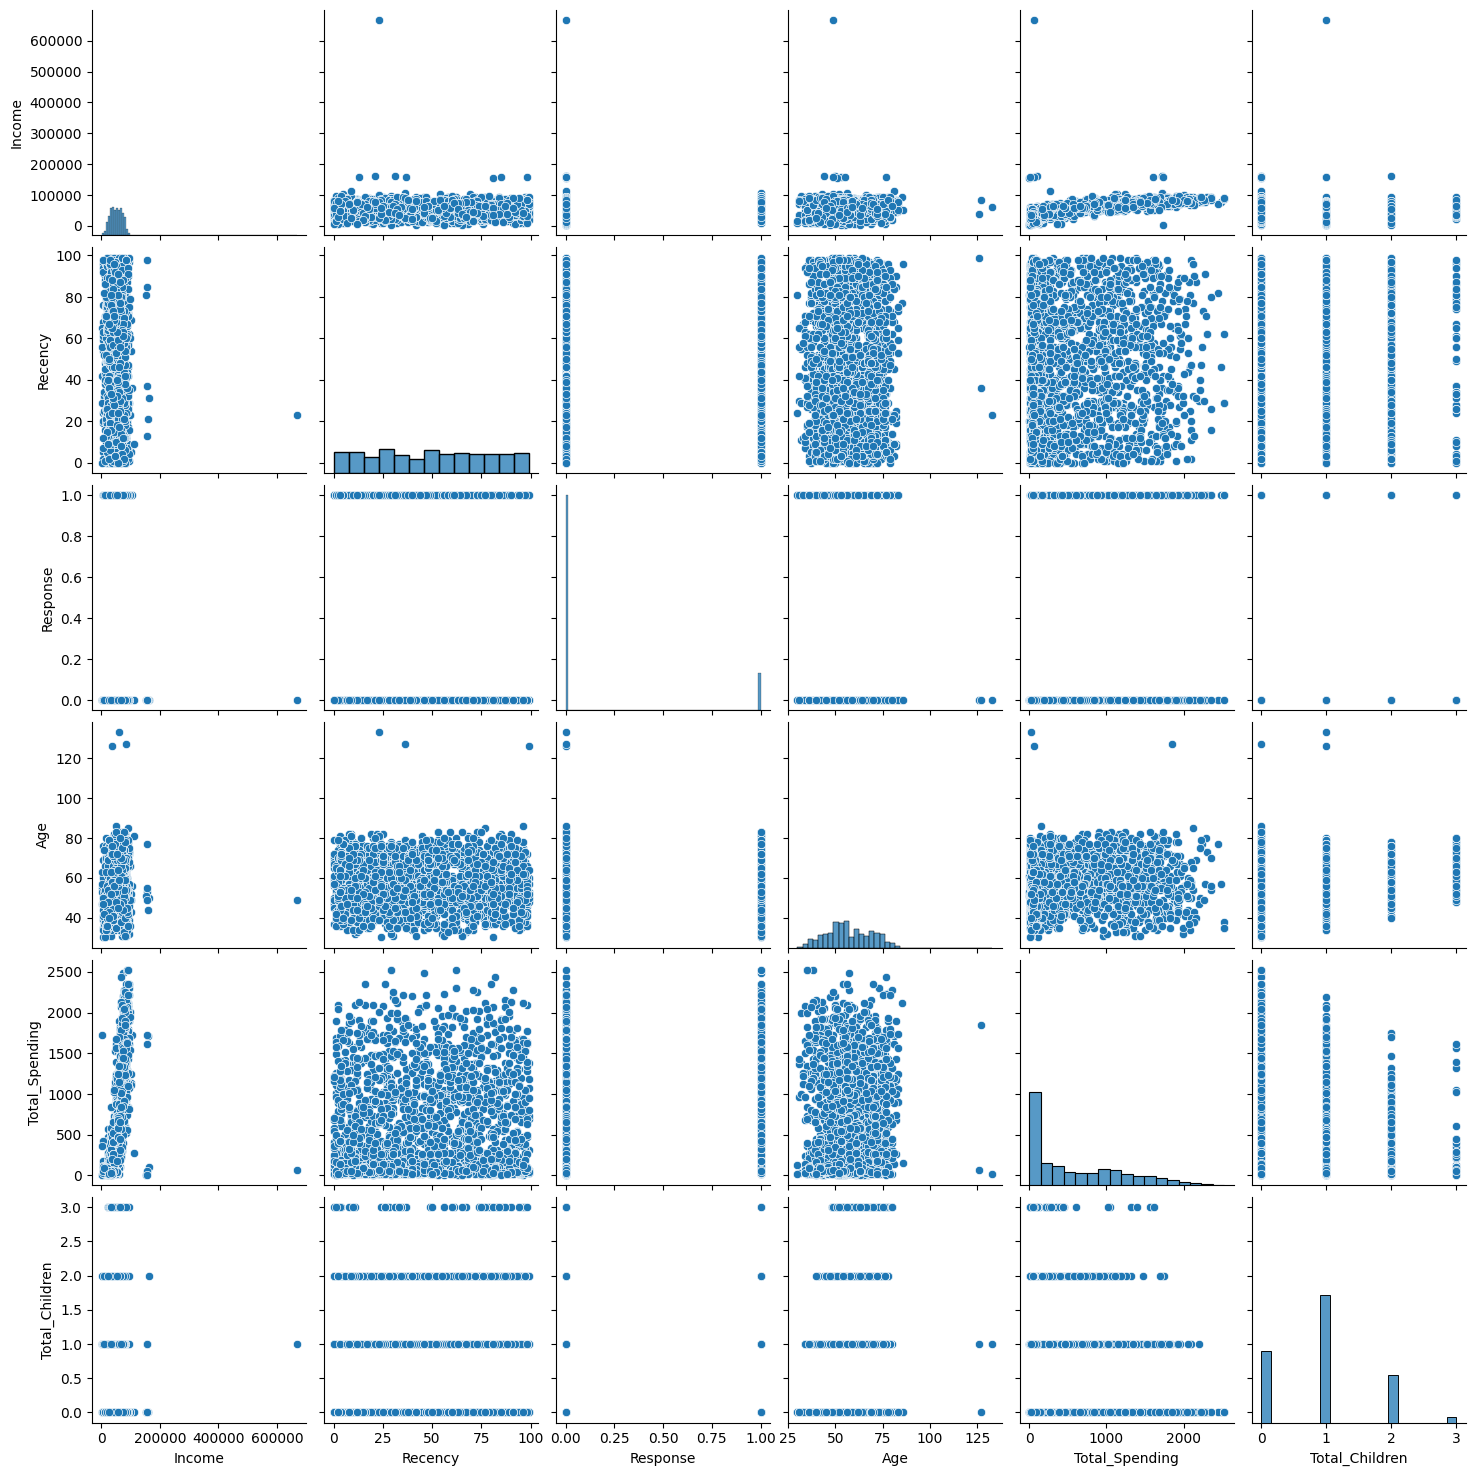

In [41]:
sns.pairplot(df_cleaned[cols])

In [43]:
# Remove Outlier
print(f'Data size with outliers : {len(df_cleaned)}')
df_cleaned = df_cleaned[(df_cleaned['Age']<90)]
df_cleaned = df_cleaned[(df_cleaned['Income']<600_000)]
print(f'Data size without outliers : {len(df_cleaned)}')

Data size with outliers : 2237
Data size without outliers : 2236


# Heatmap

<Axes: >

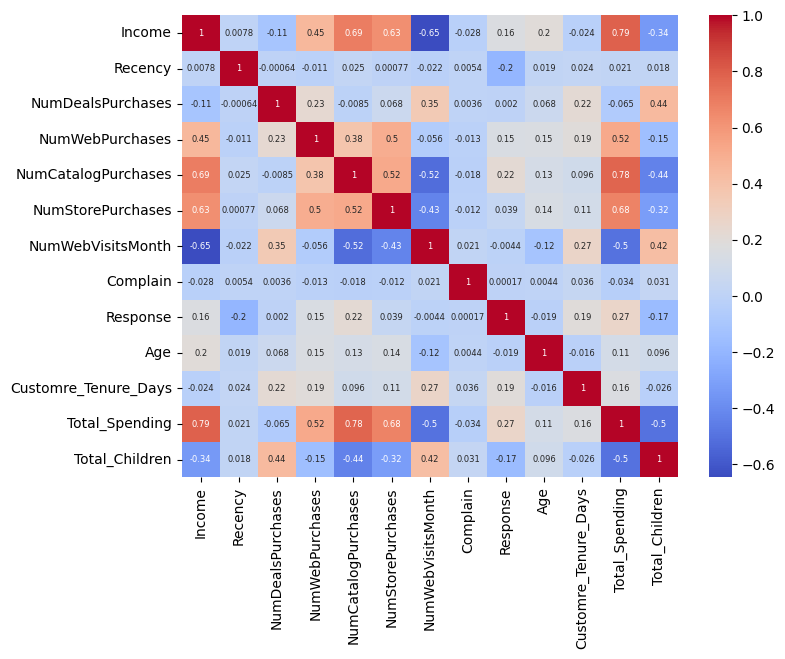

In [44]:
corr = df_cleaned.corr(numeric_only=True)

plt.figure(figsize=(8,6))
sns.heatmap(
    corr,
    annot=True,
    annot_kws={"size":6},
    cmap='coolwarm'
)

# Encoding

In [45]:
from sklearn.preprocessing import OneHotEncoder

In [47]:
ohe = OneHotEncoder()

cat_cols = ['Education','Living_with']
enc_cols = ohe.fit_transform(df_cleaned[cat_cols])

In [48]:
enc_df = pd.DataFrame(enc_cols.toarray(),columns=ohe.get_feature_names_out(cat_cols),index=df_cleaned.index)

In [50]:
df_encoded = pd.concat([df_cleaned.drop(columns=cat_cols),enc_df],axis=1)

In [52]:
X = df_encoded

# Scaling 

In [54]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [55]:
# 2D
from sklearn.decomposition import PCA

In [60]:
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

In [61]:
pca.explained_variance_ratio_

array([0.23163158, 0.11385454, 0.10405815])

Text(0.5, 0.92, '3D Projection')

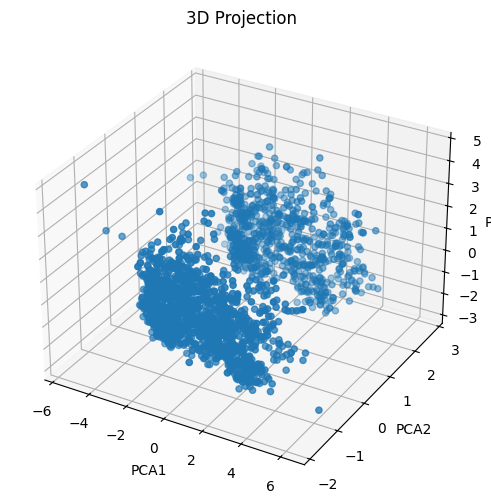

In [64]:
fig = plt.figure(figsize=(8,6))

ax = fig.add_subplot(111,projection='3d')

ax.scatter(X_pca[:,0],X_pca[:,1],X_pca[:,2])

ax.set_xlabel('PCA1')
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")
ax.set_title('3D Projection')

# Analyze K Value 

## 1. Elbow Method

In [65]:
from sklearn.cluster import KMeans
from kneed import KneeLocator

wcss = []
for k in range(1,11):
    kmeans = KMeans(n_clusters=k,random_state=42)
    kmeans.fit_predict(X_pca)
    wcss.append(kmeans.inertia_)
    

In [67]:
knee = KneeLocator(range(1,11),wcss,curve="convex",direction="decreasing")
optimal_k = knee.elbow

In [68]:
print(f"Best k = {optimal_k}")

Best k = 4


Text(0, 0.5, 'WCSS')

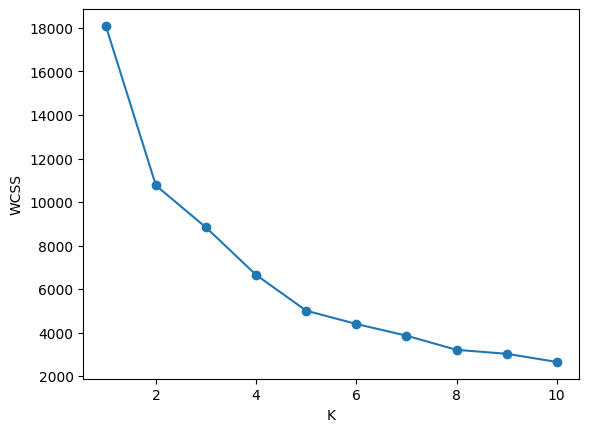

In [70]:
# Plot
plt.plot(range(1,11),wcss,marker='o')
plt.xlabel('K')
plt.ylabel('WCSS')

## 2. Silouette Score

Text(0, 0.5, 'Silhouette Score')

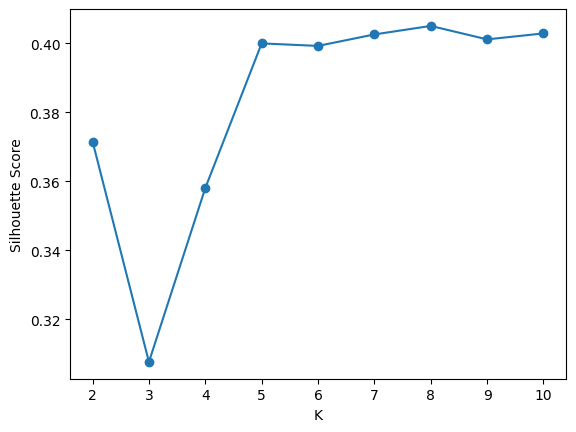

In [71]:
from sklearn.metrics import silhouette_score

scores = []

for k in range(2,11):
    kmeans = KMeans(n_clusters=k,random_state=42)
    labels = kmeans.fit_predict(X_pca)
    score = silhouette_score(X_pca,labels)
    scores.append(score)

# Plot
plt.plot(range(2,11),scores,marker='o')
plt.xlabel('K')
plt.ylabel('Silhouette Score')

Text(0, 0.5, 'SS')

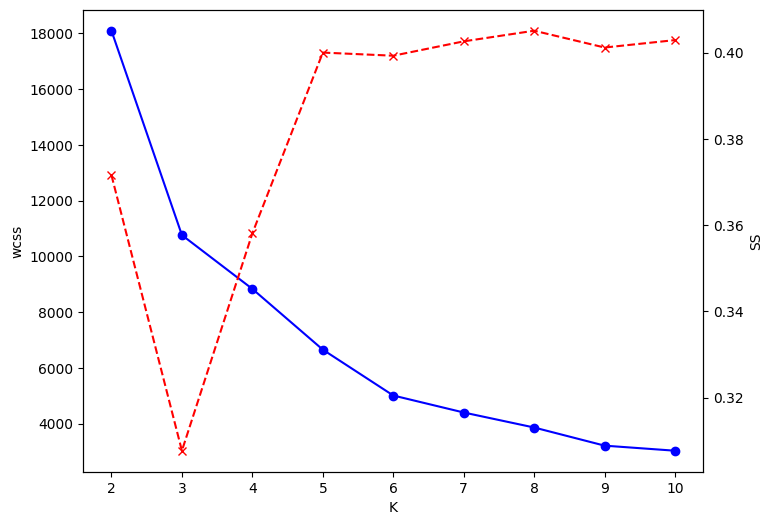

In [74]:
# Combined Plot

k_range = range(2,11)
fig ,ax1 = plt.subplots(figsize=(8,6))

ax1.plot(k_range,wcss[:len(k_range)],marker='o',color='blue')
ax1.set_xlabel('K')
ax1.set_ylabel('wcss')

ax2 = ax1.twinx()
ax2.plot(k_range,scores[:len(k_range)],marker='x',color='red',linestyle='--')
ax2.set_ylabel('SS')

# Clustering

In [75]:
# K_means

kmeans = KMeans(n_clusters=4,random_state=42)
label_kmeans = kmeans.fit_predict(X_pca)

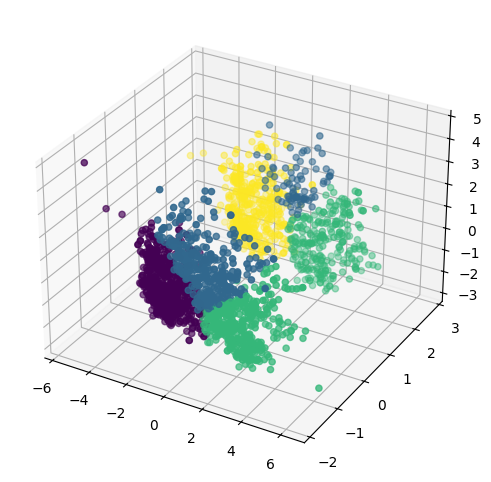

In [76]:
fig = plt.figure(figsize=(8,6))

ax = fig.add_subplot(111,projection='3d')

ax.scatter(X_pca[:,0],X_pca[:,1],X_pca[:,2],c=label_kmeans)

In [77]:
# Agglomerative Clustering
from sklearn.cluster import AgglomerativeClustering

In [78]:
agg_clf = AgglomerativeClustering(n_clusters=4,linkage='ward')
labels_agg = agg_clf.fit_predict(X_pca)

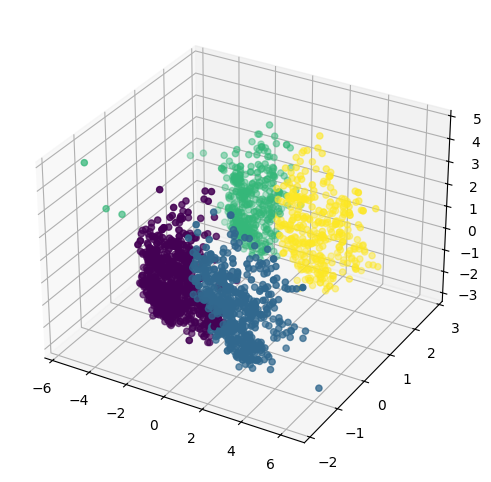

In [79]:
fig = plt.figure(figsize=(8,6))

ax = fig.add_subplot(111,projection='3d')

ax.scatter(X_pca[:,0],X_pca[:,1],X_pca[:,2],c=labels_agg)

# Characterization of Clusters

In [90]:
X['cluster'] = labels_agg

In [91]:
X.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customre_Tenure_Days,Total_Spending,Total_Children,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_with_Alone,Living_with_Partner,cluster
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0,3
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0,2
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0,1
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0,0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0,0


<Axes: xlabel='cluster', ylabel='count'>

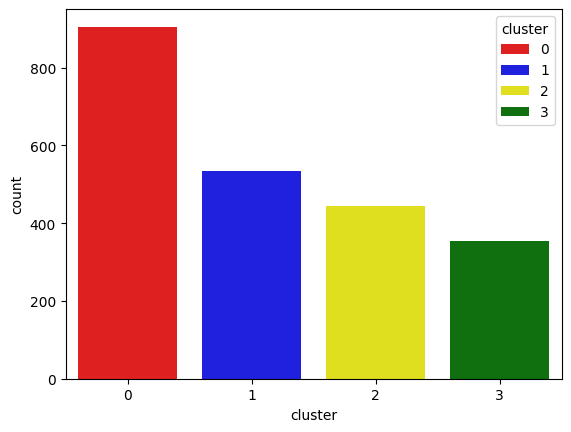

In [92]:
pal = ['red','blue','yellow','green']
sns.countplot(x=X['cluster'],palette=pal,hue=X['cluster'])

<Axes: xlabel='Total_Spending', ylabel='Income'>

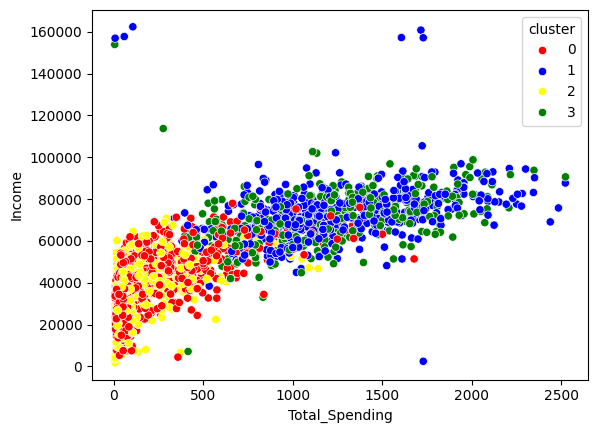

In [93]:
# Income and spending patterns

sns.scatterplot(x=X['Total_Spending'],y=X['Income'],hue=X['cluster'],palette=pal)

In [97]:
# Cluster Summary

cluster_summary = X.groupby('cluster').mean()
print(cluster_summary)

               Income    Recency  NumDealsPurchases  ...  Education_Undergraduate  Living_with_Alone  Living_with_Partner
cluster                                              ...                                                                 
0        39680.580110  48.914917           2.594475  ...                 0.146961           0.000000             1.000000
1        72808.445693  49.202247           1.958801  ...                 0.073034           0.000000             1.000000
2        36960.143018  48.319820           2.594595  ...                 0.132883           0.993243             0.006757
3        70722.681303  50.504249           1.855524  ...                 0.067989           1.000000             0.000000

[4 rows x 18 columns]
